### iShares 20+ Year Treasury Bond ETF

In [1]:
import os
import sys
import requests
import datetime as dt
import numpy as np
from dotenv import load_dotenv
from pathlib import Path
import requests
import pandas as pd
import talib as ta
import plotly.graph_objs as go

import ipywidgets as widgets
from ipywidgets import Dropdown, Text, Button, Output
from IPython.display import display

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

In [2]:
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

In [3]:
start = '1999-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')

#### TLTの時系列データを取得

In [4]:
tlt = 'TLT'

response = request_api.update_stock_timeseries_data(
    code=tlt,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [5]:
tlt_timeseries_df = request_api.get_stock_time_series_data(
    code=tlt,
    market=None,
    start=start,
    end=end
)
tlt_timeseries_df

取得件数: 6089


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1174579,TLT,None,2002-07-30,35.413033,35.578110,35.413033,35.512948,6100,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1174580,TLT,None,2002-07-31,35.851780,35.969072,35.578103,35.599822,29400,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1174581,TLT,None,2002-08-01,36.055920,36.064606,35.856092,35.856092,25000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1174582,TLT,None,2002-08-02,36.425182,36.533785,36.003805,36.125442,52800,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1174583,TLT,None,2002-08-05,36.585926,36.681497,36.425194,36.507732,61100,35.920407,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6084,1180663,TLT,None,2026-10-05,77.110001,77.260002,76.690002,77.160004,49106700,77.618303,...,78.701412,-72.457953,False,NaN,NaN,NaN,NaN,NaN,NaN,False
6085,1180664,TLT,None,2026-10-06,77.279999,77.580002,77.070000,77.169998,31085900,77.411296,...,78.433292,-74.293520,False,NaN,NaN,NaN,NaN,-85.0,NaN,False
6086,1180665,TLT,None,2026-10-07,77.150002,77.320000,76.430000,76.459999,40200000,77.134001,...,78.110772,-75.147272,False,NaN,NaN,NaN,NaN,NaN,NaN,False
6087,1180666,TLT,None,2026-10-08,77.870003,77.910004,77.070000,77.190002,49484200,77.184001,...,77.891491,-75.078972,False,NaN,NaN,NaN,NaN,NaN,NaN,True


In [6]:
def stock_prices_and_index(
        code: str,
        name: str,
        start: str,
        end: str,
        df_sp: pd.DataFrame | None = None,
        index_name: str | None = None,
        df_index: pd.DataFrame | None = None,
    ):
    # /api/v1/time_series_data/stock/
    response = request_api.get_stock_time_series_data(
        code=code,
        market=None,
        start=start,
        end=end
    )
    df_stock = pd.DataFrame(response)

    # S&P500を統合
    if df_sp is not None:
        df_sp_tmp = df_sp.copy() if df_sp is not None else pd.DataFrame()
        if "date" not in df_sp_tmp.columns:
            df_sp_tmp = df_sp_tmp.reset_index()

        df_sp_tmp["date"] = pd.to_datetime(df_sp_tmp["date"])
        df_sp_tmp = df_sp_tmp.set_index("date")
        df_sp_tmp = df_sp_tmp.loc[start:end]

    # INDEXを統合
    if df_index is not None:
        df_index_tmp = df_index.copy() if df_index is not None else pd.DataFrame()
        if "date" not in df_index_tmp.columns:
            df_index_tmp = df_index_tmp.reset_index()
        df_index_tmp["date"] = pd.to_datetime(df_index_tmp["date"])
        df_index_tmp = df_index_tmp.set_index("date")
        df_index_tmp = df_index_tmp.loc[start:end]

    # 株価時系列データを整形
    df = df_stock.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")
    df = df.loc[start:end]


    # インデックスを揃えて結合
    if df_sp is not None:
        df["MA50_SP"] = df_sp_tmp["ma50"].reindex(df.index)
        df["MA200_SP"] = df_sp_tmp["ma200"].reindex(df.index)
    if df_index is not None:
        df["MA50_" + index_name] = df_index_tmp["ma50"].reindex(df.index)
        df["MA200_" + index_name] = df_index_tmp["ma200"].reindex(df.index)

    show_plot = ShowPlot()
    fig = show_plot.create_basic_chart(
        df=df.reset_index(),
        code=code,
        name=name,
        start=start,
        end=end,
        ma5=False,
        ma25=False,
        ma50=True,
        ma100=False,
        ma150=False,
        ma200=True,
    )
    # ★ 2つのY軸を定義（左：HYMC、右：SP500 & GOLD）
    fig.update_layout(
        yaxis=dict(
            title=f"{name} Price",
            side="left"
        ),
        yaxis2=dict(
            title="SP500 / WTI",
            overlaying="y",
            side="right"
        )
    )

    # --- SP500（右軸） ---
    if df_sp is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_SP"],
                name="SP_MA50",
                line={"color": "blue", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_SP"],
                name="SP_MA200",
                line={"color": "gray", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    # --- INDEX（右軸） ---
    if df_index is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_" + index_name],
                name=index_name + "_MA50",
                line={"color": "orange", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_" + index_name],
                name=index_name + "_MA200",
                line={"color": "yellow", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    return fig

In [7]:
name = "iShares 20+ Year Treasury Bond ETF"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_index(
    code=tlt,
    name=name,
    start=start,
    end=end,
    df_sp=None,
    df_index=None
)
fig.show()

取得件数: 651


In [8]:
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"{tlt}_{start}_{end}.png"
fig.write_image(str(output_path), width=1600, height=900, scale=2)
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/TLT_2025-01-01_2026-10-10.png


#### 時系列データを保存

In [9]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{tlt}_data_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"

df = tlt_timeseries_df.copy()
df = df.reset_index()
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df = df.loc['2026-01-01':end]
df.to_csv(output_path)
df.head()

,index,id,stock_code,stock_market,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,5895,1180474,TLT,None,84.096558,84.463754,84.086893,84.454089,40731300,84.815478,...,84.307817,-87.543755,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-05,5896,1180475,TLT,None,84.512062,84.570037,84.173861,84.241501,30178000,84.637681,...,84.279594,-87.458380,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-06,5897,1180476,TLT,None,84.338135,84.396110,83.970946,84.212519,39015200,84.483074,...,84.302942,-87.151029,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-07,5898,1180477,TLT,None,84.830948,85.043534,84.531399,84.879258,39930900,84.502401,...,84.301548,-85.947238,False,NaN,NaN,NaN,NaN,NaN,-52.410256,False
2026-01-08,5899,1180478,TLT,None,84.405777,84.599040,84.309149,84.386454,28204900,84.434764,...,84.273640,-85.486212,False,NaN,NaN,NaN,NaN,NaN,NaN,False


{'fib_levels_down': {'1.000': np.float64(76.43000030517578),
  '1.272': np.float64(73.70854124171063),
  '1.382': np.float64(72.60795117927988),
  '1.618': np.float64(70.24668522715572)},
 'fib_levels_up': {'1.272': np.float64(89.15682357255689),
  '1.382': np.float64(90.25741363498764),
  '1.618': np.float64(92.6186795871118),
  '2.000': np.float64(96.4407287130077)},
 'swing_high': np.float64(86.43536450909174),
 'swing_low': np.float64(76.43000030517578),
 'df_with_fib':           date  index       id stock_code stock_market       open       high  \
 0   2026-01-02   5895  1180474        TLT         None  84.096558  84.463754   
 1   2026-01-05   5896  1180475        TLT         None  84.512062  84.570037   
 2   2026-01-06   5897  1180476        TLT         None  84.338135  84.396110   
 3   2026-01-07   5898  1180477        TLT         None  84.830948  85.043534   
 4   2026-01-08   5899  1180478        TLT         None  84.405777  84.599040   
 ..         ...    ...      ...     

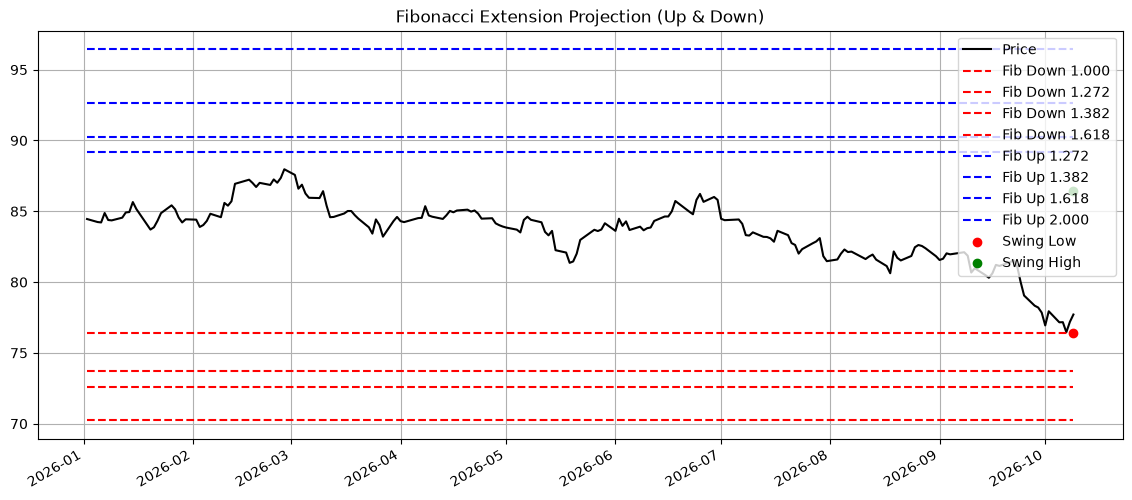

In [10]:
fib_result = fibonacci_extension.compute_fibonacci_extension(df.copy().reset_index())
fib_result

In [11]:
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{tlt}_fibonacci_extension_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
fib_result["plot_obj"].savefig(output_path, dpi=300, bbox_inches="tight")